# 06 — V4: representation, acquisition search, bounds and CMA

This notebook validates saved V4 experiments and generates analysis only. It never launches optimisation or downloads data. The frozen protocol is `docs/FOLLOWUP_PROTOCOL_V4.md`. The group used these controls to assess representation, numerical acquisition search and CMA behaviour.

The main comparison uses 100 charged calls including 20 common initial points. The 300-call CMA extension is a within-CMA comparison. V4 uses 20 primary designs, ten supporting designs, identity/Q404/Q505/Q606 and five CMA search replicates. Pointwise 95% intervals resample complete initial-design groups (5000 resamples, seed 4129), conditional on these rotations. No equivalence or family-wide significance claim is made.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image, Markdown
from bo_vs_es.followup_v4_analysis import export_analysis
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/bo_vs_es").exists())
OUT = ROOT / "results/followup_v4"
analysis = export_analysis()
pd.set_option("display.float_format", lambda x: f"{x:.5g}")
def read(name):
    path = OUT / f"{name}.csv"
    if not path.exists() or path.stat().st_size < 2:
        return pd.DataFrame()
    return pd.read_csv(path)
def show(name, columns=None, block=None):
    frame = read(name)
    if frame.empty:
        print(name + ": no eligible completed results yet.")
        return
    if block is not None:
        frame = frame[frame.block.eq(block)]
    if columns is not None:
        frame = frame[columns]
    with pd.option_context("display.max_rows", None, "display.max_columns", None, "display.max_colwidth", None, "display.width", 180):
        display(frame)
def picture(name):
    path = OUT / f"{name}.png"
    if path.exists():
        display(Image(filename=str(path)))
CI = ["design_groups", "estimate", "low", "high"]
display(pd.Series({k:analysis[k] for k in ["status","planned_runs","complete_runs","search_calls","assessment_calls","all_attempt_search_calls"]}).to_frame("value"))
coverage = read("coverage")
display(coverage.groupby("block").agg(planned=("planned","sum"),complete=("complete","sum"),eligible_designs=("complete_group","sum")))
if analysis["status"] != "complete":
    print("PARTIAL STUDY: coverage above limits every conclusion. Missing results are not null effects.")
gate = ROOT / "artifacts/rotation-followup-v4/timing_gate.json"
if gate.exists():
    value=json.loads(gate.read_text())
    display(pd.Series({k:value[k] for k in ["projected_confirmation_s","remaining_allowance_s","fits_allowance","headroom"]}).to_frame("timing_gate"))

/Users/mihirsinha/Downloads/repo/Dsa4212-final-project-bayesian-vs-evolutionary/.venv/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


,value
status,complete
planned_runs,3160
complete_runs,3160
search_calls,796000
assessment_calls,10560
all_attempt_search_calls,802000


,planned,complete,eligible_designs
block,,,
battery_bo,400,400,20
battery_bound,80,80,10
cma_ball,800,800,20
cma_box,1600,1600,20
quadratic_bo,200,200,10
quadratic_bound,80,80,10


,timing_gate
projected_confirmation_s,10977
remaining_allowance_s,14140
fits_allowance,True
headroom,1.25


## Shared-history development replays

Histories come from development identity scalar-continuous runs at 20/40/80 observations, compared with Q101. They are not confirmation or recovered original acquisition RNG states. Independent fits compare kernels at upper bounds 5 and 20 on shared physical queries and pools. Scalar common-fit controls isolate kernel mathematics. Same pool index does not imply identical acquisition functions; candidate distance does not measure objective quality.

The fit-diagnostics table retains the original independent fits in both replay modes. For common-fit prediction/acquisition controls, both models instead use the identity fitted state; the listed Q101 fit is a reference diagnostic, not a second fit used by that control.

In [2]:
show("development_replays", ["objective","design","observations","kernel","upper","mode","posterior_mean_max_abs","log_ei_max_abs","max_pool_score_difference","pool_indices","candidate_distance"])
show("development_replay_fits",["objective","design","observations","kernel","upper","mode","orientation","lengthscales","fit_status"])

,objective,design,observations,kernel,upper,mode,posterior_mean_max_abs,log_ei_max_abs,max_pool_score_difference,pool_indices,candidate_distance
0,battery,0,20,iso,5,independent_fits,1.7031e-13,1.7207e-10,1.2894e-09,"[1356, 1356]",0
1,battery,0,20,iso,5,common_fit,6.0396e-14,2.5068e-11,2.3209e-09,"[1356, 1356]",0
2,battery,0,20,iso,20,independent_fits,1.9273e-13,9.8879e-11,1.2942e-09,"[1356, 1356]",0
3,battery,0,20,iso,20,common_fit,6.7502e-14,1.7016e-10,8.2809e-10,"[1356, 1356]",0
4,battery,0,20,ard,5,independent_fits,2.0203,158.83,1408.6,"[1658, 2465]",0.28707
5,battery,0,20,ard,20,independent_fits,2.1219,280.91,2265.9,"[3696, 2465]",0.72812
6,battery,0,40,iso,5,independent_fits,5.3513e-14,1.2932e-12,4.2746e-11,"[2901, 2901]",0
7,battery,0,40,iso,5,common_fit,6.3949e-14,2.1387e-12,1.225e-11,"[2901, 2901]",0
8,battery,0,40,iso,20,independent_fits,6.2172e-14,3.7232e-12,8.4484e-12,"[2901, 2901]",0
9,battery,0,40,iso,20,common_fit,1.7764e-14,4.8317e-13,1.9583e-11,"[2901, 2901]",0


,objective,design,observations,kernel,upper,mode,orientation,lengthscales,fit_status
0,battery,0,20,iso,5,independent_fits,identity,[2.1621549296575466],OptimizationStatus.SUCCESS
1,battery,0,20,iso,5,independent_fits,Q101,[2.1621549296577443],OptimizationStatus.SUCCESS
2,battery,0,20,iso,5,common_fit,identity,[2.1621549296575466],OptimizationStatus.SUCCESS
3,battery,0,20,iso,5,common_fit,Q101,[2.1621549296577443],OptimizationStatus.SUCCESS
4,battery,0,20,iso,20,independent_fits,identity,[2.162196675606053],OptimizationStatus.SUCCESS
5,battery,0,20,iso,20,independent_fits,Q101,[2.1621966756057533],OptimizationStatus.SUCCESS
6,battery,0,20,iso,20,common_fit,identity,[2.162196675606053],OptimizationStatus.SUCCESS
7,battery,0,20,iso,20,common_fit,Q101,[2.1621966756057533],OptimizationStatus.SUCCESS
8,battery,0,20,ard,5,independent_fits,identity,"[0.6368811144942933, 1.1348304358790804, 4.999999132364801, 1.0153643242774546, 4.999998247843835]",OptimizationStatus.SUCCESS
9,battery,0,20,ard,5,independent_fits,Q101,"[1.757354075099355, 1.687142075347252, 2.3515979875010666, 1.0337098611507167, 2.420817425438368]",OptimizationStatus.SUCCESS


## BO rotation effects and kernel-by-search interaction

$R=\log_{10}(L_Q/L_I)$: positive means worse after rotation. Compare each kernel's $R_{pool}-R_{continuous}$, then subtract the scalar change from the ARD change. This paired interaction tests how the acquisition intervention modifies the kernel contrast. It does not uniquely isolate representation, fitting or numerical causes. All methods use the same charged initial information; pool methods share indexed physical pools even after histories diverge.

**Completed V4 finding.** Battery ARD effects remain positive with continuous search (0.127–0.169 log10 loss) and pool search (0.085–0.133), with all six pointwise intervals above zero. Continuous acquisition optimisation is therefore not necessary for these ARD effects. The battery kernel-by-search interaction is negative with an interval excluding zero only for Q606: −0.111 [−0.169, −0.053]. This does not separate metric representation from fitting and bounds.

battery_bo


,method,orientation,design_groups,estimate,low,high
0,bo_ard,404,20,0.13421,0.056672,0.2198
1,bo_ard,505,20,0.12711,0.044431,0.23574
2,bo_ard,606,20,0.16887,0.075469,0.28694
3,bo_ard_pool,404,20,0.13341,0.05476,0.21954
4,bo_ard_pool,505,20,0.10919,0.041773,0.18116
5,bo_ard_pool,606,20,0.085179,0.019626,0.15649
6,bo_iso,404,20,-0.017714,-0.05905,0.02051
7,bo_iso,505,20,0.009951,-0.025081,0.045669
8,bo_iso,606,20,-0.027091,-0.11109,0.062545
9,bo_iso_pool,404,20,-1.0849e-16,-8.2691e-16,3.9296e-16


iso_pool_minus_continuous_intervals


,orientation,design_groups,estimate,low,high
0,404,20,0.017714,-0.02051,0.05905
1,505,20,-0.009951,-0.045669,0.025081
2,606,20,0.027091,-0.062545,0.11109


ard_pool_minus_continuous_intervals


,orientation,design_groups,estimate,low,high
0,404,20,-0.00080396,-0.11372,0.12465
1,505,20,-0.017925,-0.11607,0.076694
2,606,20,-0.083686,-0.17613,0.015179


... (6 outputs left out)

ard_pool_minus_continuous_intervals


,orientation,design_groups,estimate,low,high
3,404,10,-1.6082,-1.9308,-1.3012
4,505,10,-1.6416,-1.8865,-1.4197
5,606,10,-1.7257,-2.0025,-1.4382


kernel_by_search_intervals


,orientation,design_groups,estimate,low,high
3,404,10,-1.6357,-2.02,-1.2427
4,505,10,-1.6488,-1.9391,-1.3624
5,606,10,-1.6667,-2.0353,-1.286


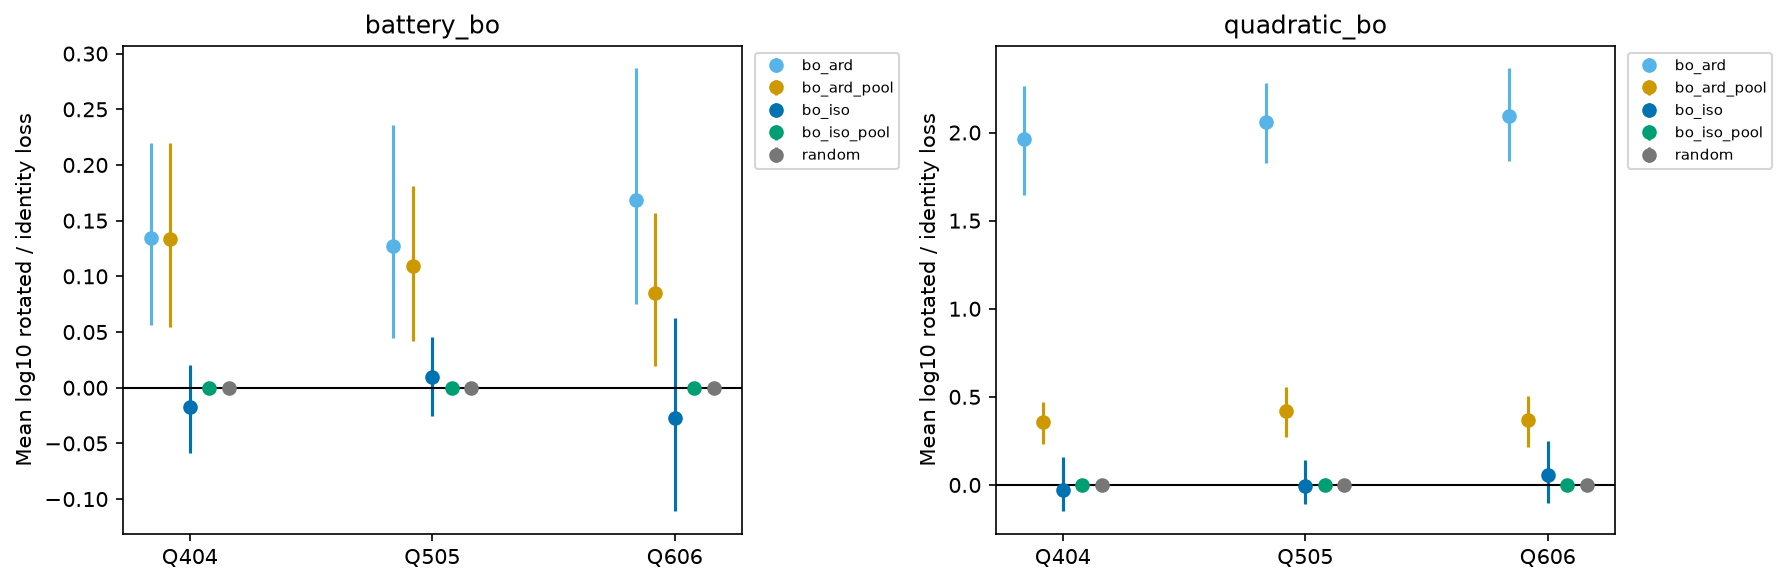

In [3]:
for block in ["battery_bo", "quadratic_bo"]:
    print(block)
    show("rotation_intervals", ["method","orientation",*CI], block)
    for name in ["iso_pool_minus_continuous_intervals","ard_pool_minus_continuous_intervals","kernel_by_search_intervals"]:
        print(name)
        show(name,["orientation",*CI],block)
picture("bo_rotation_effects")

## Matching paths is distinct from quality and cost

The path figure shows median within-design averages over rotations, with a labelled $10^{-16}$ plotting floor. Final-distance tables describe paths, not additional independent designs. Pool-quality ratios are $\log_{10}(L_{pool}/L_{continuous})$; negative favours the pool. Timing differences are pool minus continuous search seconds. Intervals including zero do not establish equivalence.

The call convergence panel aggregates within designs before taking a median; time trajectories remain individual. Search includes objective evaluations, fitting, acquisition, rejected proposals, updates and logging. The simulator is cheap, so overhead matters. No equal-time stopping comparison is claimed.

**Completed V4 finding.** Scalar-pool final distances are below 1e−15, while ARD-pool paths diverge. Scalar-pool battery quality intervals include zero in all orientations. On the quadratic, both pool kernels have higher loss than their continuous counterparts in every orientation (all eight intervals above zero). In particular, ARD-pool identity loss is about 88 times the continuous identity loss geometrically (log ratio 1.945 [1.674, 2.216]). Its smaller rotation contrast partly reflects worse identity performance, not improved optimisation. Battery descriptive median search times are 2.37 s scalar-pool versus 20.65 s continuous, and 3.11 s ARD-pool versus 25.45 s continuous.

,block,method,median,max,size
0,battery_bo,bo_ard,1.1937,1.7722,60
1,battery_bo,bo_ard_pool,1.0816,1.6109,60
2,battery_bo,bo_iso,0.87274,1.6905,60
3,battery_bo,bo_iso_pool,5.2019e-16,9.9775e-16,60
4,battery_bo,random,2.1572e-16,4.8967e-16,60
5,battery_bound,bo_ard_pool,0.91824,1.5851,30
6,battery_bound,bo_iso_pool,4.4919e-16,9.9775e-16,30
7,quadratic_bo,bo_ard,0.85296,1.8356,30
8,quadratic_bo,bo_ard_pool,0.77529,1.5919,30
9,quadratic_bo,bo_iso,1.1783,1.9213,30


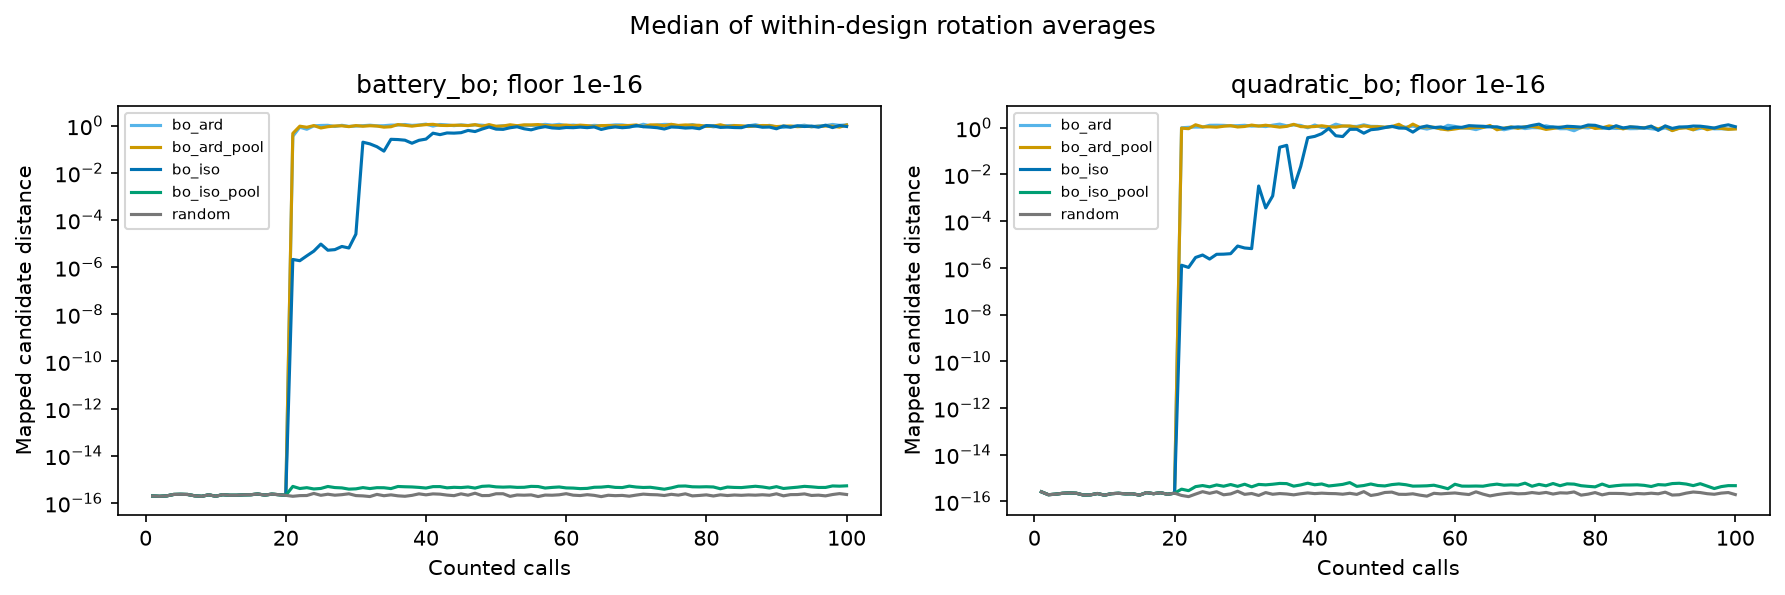

,block,kernel,orientation,design_groups,estimate,low,high
0,battery_bo,ard,-1,20,0.11435,0.059363,0.16268
1,battery_bo,ard,404,20,0.11355,-0.004649,0.23341
2,battery_bo,ard,505,20,0.096425,0.026196,0.15668
3,battery_bo,ard,606,20,0.030665,-0.05288,0.11264
4,battery_bo,iso,-1,20,-0.023283,-0.12087,0.073955
5,battery_bo,iso,404,20,-0.0055693,-0.081475,0.076965
6,battery_bo,iso,505,20,-0.033234,-0.13678,0.065728
7,battery_bo,iso,606,20,0.0038082,-0.13371,0.10907
8,quadratic_bo,ard,-1,10,1.9448,1.6738,2.216
9,quadratic_bo,ard,404,10,0.33666,0.18201,0.50683


,block,kernel,orientation,design_groups,estimate,low,high
0,battery_bo,ard,-1,20,-24.15,-26.001,-22.412
1,battery_bo,ard,404,20,-22.372,-24.437,-20.265
2,battery_bo,ard,505,20,-23.257,-25.843,-20.817
3,battery_bo,ard,606,20,-21.159,-22.779,-19.719
4,battery_bo,iso,-1,20,-19.806,-21.494,-18.362
5,battery_bo,iso,404,20,-19.91,-21.749,-18.395
6,battery_bo,iso,505,20,-19.327,-20.811,-18.04
7,battery_bo,iso,606,20,-19.496,-21.155,-18.095
8,quadratic_bo,ard,-1,10,-22.118,-23.243,-21.024
9,quadratic_bo,ard,404,10,-20.119,-21.006,-19.387


,method,orientation,runs,design_groups,median_loss,median_search_s,median_objective_s,median_overhead_s
0,bo_ard,-1,20,20,2.5497e-05,27.737,0.14424,27.594
1,bo_ard,404,20,20,2.906e-05,23.989,0.14426,23.842
2,bo_ard,505,20,20,3.1769e-05,25.717,0.14514,25.574
3,bo_ard,606,20,20,3.8591e-05,22.915,0.1447,22.77
4,bo_ard_pool,-1,20,20,3.5346e-05,4.2689,0.1432,4.1257
5,bo_ard_pool,404,20,20,4.4669e-05,2.9417,0.14361,2.7977
6,bo_ard_pool,505,20,20,4.5036e-05,2.9184,0.14352,2.775
7,bo_ard_pool,606,20,20,4.1236e-05,3.1285,0.14394,2.9847
8,bo_iso,-1,20,20,4.1706e-05,20.85,0.14345,20.706
9,bo_iso,404,20,20,4.4406e-05,21.097,0.14361,20.955


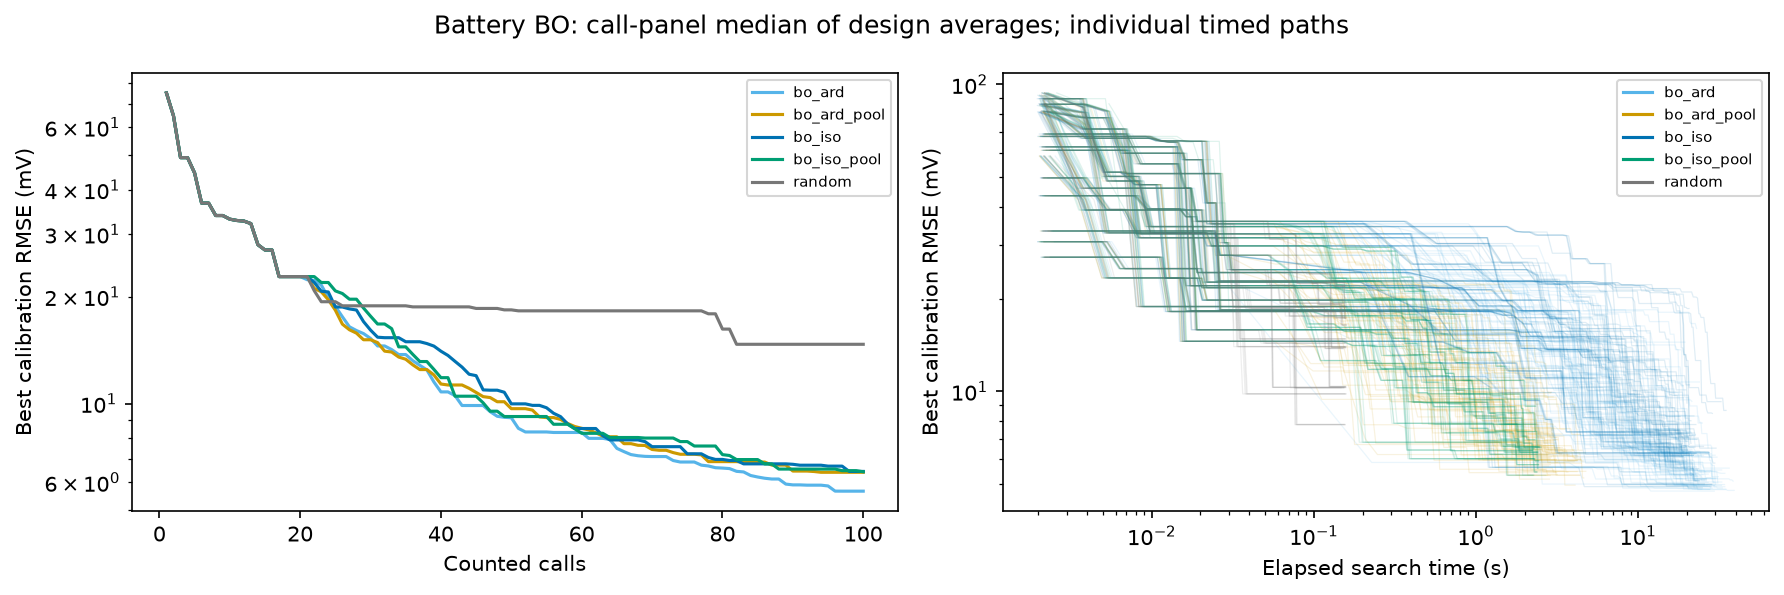

In [4]:
show("final_path_summary")
picture("path_matching")
show("pool_quality_intervals", ["block","kernel","orientation",*CI])
show("pool_timing_intervals", ["block","kernel","orientation",*CI])
show("quality_and_timing", ["method","orientation","runs","design_groups","median_loss","median_search_s","median_objective_s","median_overhead_s"], "battery_bo")
picture("quality_and_time")

## Pool-only bound sensitivity and numerical health

Compare upper bounds 20 and 5 for scalar/ARD pool BO on ten matching supporting designs. The quality effect is $\log_{10}(L_{20}/L_5)$ and the rotation contrast is $R_{20}-R_5$. Require complete baseline and sensitivity groups. This does not estimate continuous-search bound sensitivity. Bounds can affect fitting numerics as well as admissible metrics.

Occupancy counts fits with any scale within 1% of that run's actual upper bound (4.95 or 19.8), not individual scale entries. Report STOPPED fits and warnings alongside losses. A bound effect or absence of one does not uniquely establish a representation mechanism.

**Completed V4 finding.** Every bound-induced rotation-change interval includes zero; ten designs leave substantial uncertainty. Increasing the bound improves quadratic ARD-pool absolute quality in the three rotated cases, with log ratios −0.264, −0.309 and −0.185 (each interval below zero), but does not uniquely identify the rotation mechanism. There are 69 STOPPED fits across 51,200 confirmation fits; recorded warning lists are empty. These runs completed and remain included. Bound occupancy counts dependent fits, not independent replications.

In [5]:
show("bound_quality_intervals",["objective","method","orientation",*CI])
show("bound_rotation_intervals",["objective","method","orientation",*CI])
show("health_summary")
show("fit_statuses")

,objective,method,orientation,design_groups,estimate,low,high
0,battery,bo_ard_pool,-1,10,-0.028947,-0.13368,0.074482
1,battery,bo_ard_pool,404,10,-0.02215,-0.10052,0.04405
2,battery,bo_ard_pool,505,10,-0.045036,-0.097922,-0.0030569
3,battery,bo_ard_pool,606,10,-0.034,-0.11772,0.060982
4,battery,bo_iso_pool,-1,10,0,0,0
5,battery,bo_iso_pool,404,10,0,0,0
6,battery,bo_iso_pool,505,10,0,0,0
7,battery,bo_iso_pool,606,10,0,0,0
8,quadratic,bo_ard_pool,-1,10,-0.066119,-0.18042,0
9,quadratic,bo_ard_pool,404,10,-0.26418,-0.44057,-0.017802


,objective,method,orientation,design_groups,estimate,low,high
0,battery,bo_ard_pool,404,10,0.0067971,-0.13606,0.15516
1,battery,bo_ard_pool,505,10,-0.01609,-0.1128,0.082422
2,battery,bo_ard_pool,606,10,-0.0050532,-0.18243,0.1862
3,battery,bo_iso_pool,404,10,0,0,0
4,battery,bo_iso_pool,505,10,0,0,0
5,battery,bo_iso_pool,606,10,0,0,0
6,quadratic,bo_ard_pool,404,10,-0.19806,-0.36497,0.033927
7,quadratic,bo_ard_pool,505,10,-0.24295,-0.45581,0.0087519
8,quadratic,bo_ard_pool,606,10,-0.11912,-0.30069,0.072277
9,quadratic,bo_iso_pool,404,10,-3.1341e-16,-1.109e-15,3.2787e-16


,block,method,lengthscale_upper,fits,near_upper,near_lower,warnings
0,battery_bo,bo_ard,5,6400,2343,0,0
1,battery_bo,bo_ard_pool,5,6400,2254,0,0
2,battery_bo,bo_iso,5,6400,0,0,0
3,battery_bo,bo_iso_pool,5,6400,0,0,0
4,battery_bound,bo_ard_pool,20,3200,816,0,0
5,battery_bound,bo_iso_pool,20,3200,0,0,0
6,quadratic_bo,bo_ard,5,3200,3097,0,0
7,quadratic_bo,bo_ard_pool,5,3200,3116,0,0
8,quadratic_bo,bo_iso,5,3200,959,0,0
9,quadratic_bo,bo_iso_pool,5,3200,948,0,0


,block,method,fit_status,fits
0,battery_bo,bo_ard,OptimizationStatus.STOPPED,11
1,battery_bo,bo_ard,OptimizationStatus.SUCCESS,6389
2,battery_bo,bo_ard_pool,OptimizationStatus.STOPPED,4
3,battery_bo,bo_ard_pool,OptimizationStatus.SUCCESS,6396
4,battery_bo,bo_iso,OptimizationStatus.SUCCESS,6400
5,battery_bo,bo_iso_pool,OptimizationStatus.SUCCESS,6400
6,battery_bound,bo_ard_pool,OptimizationStatus.SUCCESS,3200
7,battery_bound,bo_iso_pool,OptimizationStatus.SUCCESS,3200
8,quadratic_bo,bo_ard,OptimizationStatus.STOPPED,26
9,quadratic_bo,bo_ard,OptimizationStatus.SUCCESS,3174


## CMA: orientation versus independent-search variability

CMA uses controlled pycma variants: population eight, initial sigma .3, isotropic starting covariance, disabled active updates/mirrors/additional diagonal decoding. Diagonal `cc_sep`, `c1_sep`, `cmu_sep` match full constants; native covariance update mechanics remain distinct. This is not a benchmark of every default or tuned CMA implementation.

Signed effects below have design-bootstrap uncertainty. Independent identity pairs overlap and are descriptive. Figure dots are within-design means of absolute log ratios, with bars showing means across designs. Similar absolute variability does not establish equivalence or prevent a consistent signed effect.

**Completed V4 finding.** At 100 calls, signed ball effects include zero for both variants and absolute contrasts resemble identity-search variation. At 300 calls, diagonal effects are 0.067 [0.034, 0.104], 0.079 [0.044, 0.115] and 0.081 [0.042, 0.124] for Q404/Q505/Q606: about 17–20% higher geometric-mean loss than identity. Full-CMA estimates remain near zero with intervals spanning zero. This supports a consistent diagonal effect in these cases, without an equivalence claim for full CMA.

cma_ball


,method,handler,calls,orientation,design_groups,estimate,low,high
21,cma_diag,resample,100,404,20,-0.04037,-0.094269,0.020697
22,cma_diag,resample,100,505,20,-0.034413,-0.079076,0.0097612
23,cma_diag,resample,100,606,20,-0.05502,-0.12124,0.014657
24,cma_diag,resample,300,404,20,0.067159,0.034091,0.10369
25,cma_diag,resample,300,505,20,0.079006,0.044089,0.11508
26,cma_diag,resample,300,606,20,0.080851,0.042442,0.12394
27,cma_full,resample,100,404,20,0.0086573,-0.0518,0.066581
28,cma_full,resample,100,505,20,0.0064627,-0.048003,0.061541
29,cma_full,resample,100,606,20,0.028936,-0.032612,0.097337
30,cma_full,resample,300,404,20,0.0025158,-0.022796,0.028776


cma_box


,method,handler,calls,orientation,design_groups,estimate,low,high
33,cma_diag,project,100,404,20,0.0092986,-0.059559,0.074873
34,cma_diag,project,100,505,20,0.029049,-0.030323,0.095879
35,cma_diag,project,100,606,20,-0.01285,-0.096644,0.073572
36,cma_diag,project,300,404,20,0.09028,0.0077007,0.17579
37,cma_diag,project,300,505,20,0.10679,0.01371,0.20192
38,cma_diag,project,300,606,20,0.0935,0.010648,0.18984
39,cma_diag,resample,100,404,20,0.036646,-0.048558,0.12185
40,cma_diag,resample,100,505,20,0.011269,-0.052133,0.075806
41,cma_diag,resample,100,606,20,0.0092159,-0.068263,0.09079
42,cma_diag,resample,300,404,20,0.077108,0.012506,0.15627


,block,method,handler,calls,comparison,designs,mean_absolute_log_ratio
0,cma_ball,cma_diag,resample,100,I vs I,20,0.29414
1,cma_ball,cma_diag,resample,100,Q404 vs I,20,0.26638
2,cma_ball,cma_diag,resample,100,Q505 vs I,20,0.28226
3,cma_ball,cma_diag,resample,100,Q606 vs I,20,0.31499
4,cma_ball,cma_diag,resample,300,I vs I,20,0.084971
5,cma_ball,cma_diag,resample,300,Q404 vs I,20,0.11457
6,cma_ball,cma_diag,resample,300,Q505 vs I,20,0.14131
7,cma_ball,cma_diag,resample,300,Q606 vs I,20,0.13101
8,cma_ball,cma_full,resample,100,I vs I,20,0.24729
9,cma_ball,cma_full,resample,100,Q404 vs I,20,0.23039


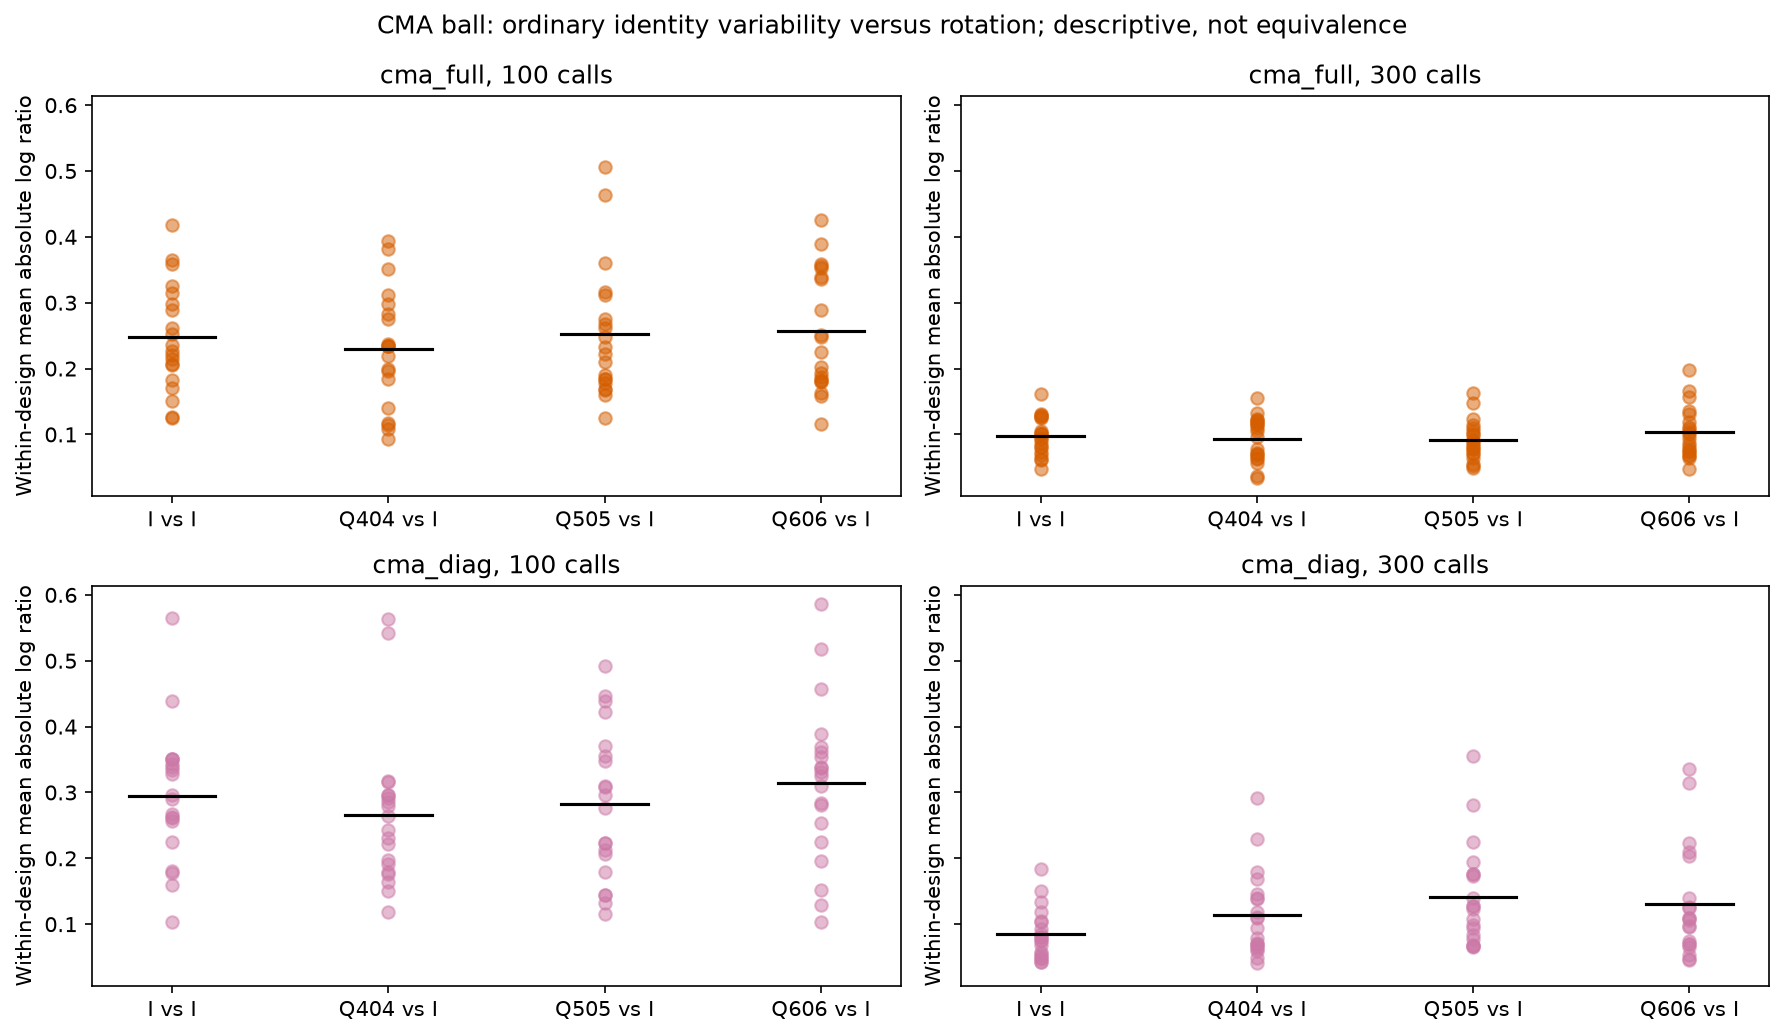

In [6]:
for block in ["cma_ball","cma_box"]:
    print(block)
    show("rotation_intervals",["method","handler","calls","orientation",*CI],block)
show("cma_variability_summary")
picture("cma_variability")

## CMA 100/300-call changes and boundaries

Pair each trajectory's checkpoints before averaging replicates and bootstrapping designs. Negative $\log_{10}(L_{300}/L_{100})$ means improvement. Extra calls and changes in step size accompany covariance adaptation; its spectral ratio contains no directional information. Neither alignment nor causal adaptation benefit is established.

On the same physical box, $B_n=R_{project,n}-R_{resample,n}$. Compare $B_{300}-B_{100}$ directly rather than comparing whether separate intervals include zero. This contrast is predeclared for V4. It is CMA-specific, not a percentage of BO/CMA sensitivity attributable to boundaries. Disappearance cannot be inferred from an interval containing zero.

**Completed V4 finding.** All planned paired loss changes favour 300 calls. On the ball, full-CMA log changes range from −0.482 to −0.512; diagonal changes are −0.509 at identity and −0.373 to −0.401 after rotation. All same-box boundary interactions and directly paired budget-change intervals include zero. V4 therefore does not establish the V3 Q202 attenuation on these new rotations/designs; it does not prove absence of a boundary effect. Increasing anisotropy alone still does not establish useful alignment.

,block,method,handler,orientation,design_groups,estimate,low,high
0,cma_ball,cma_diag,resample,-1,20,-0.50897,-0.55792,-0.46235
1,cma_ball,cma_diag,resample,404,20,-0.40145,-0.45293,-0.35211
2,cma_ball,cma_diag,resample,505,20,-0.39555,-0.4387,-0.35003
3,cma_ball,cma_diag,resample,606,20,-0.3731,-0.41831,-0.32708
4,cma_ball,cma_full,resample,-1,20,-0.48206,-0.53662,-0.42756
5,cma_ball,cma_full,resample,404,20,-0.4882,-0.53714,-0.4396
6,cma_ball,cma_full,resample,505,20,-0.49017,-0.53883,-0.44332
7,cma_ball,cma_full,resample,606,20,-0.51234,-0.55818,-0.46164
8,cma_box,cma_diag,project,-1,20,-0.45891,-0.55005,-0.36995
9,cma_box,cma_diag,project,404,20,-0.37792,-0.44233,-0.31398


,method,orientation,calls,median_rmse,mean_boundary_fraction
28,cma_diag,-1,100,0.010704,0
29,cma_diag,404,100,0.0097997,0
30,cma_diag,505,100,0.010585,0
31,cma_diag,606,100,0.0099428,0
32,cma_diag,-1,300,0.0060453,0
33,cma_diag,404,300,0.006331,0
34,cma_diag,505,300,0.0063357,0
35,cma_diag,606,300,0.0063994,0
36,cma_full,-1,100,0.010437,0
37,cma_full,404,100,0.01058,0


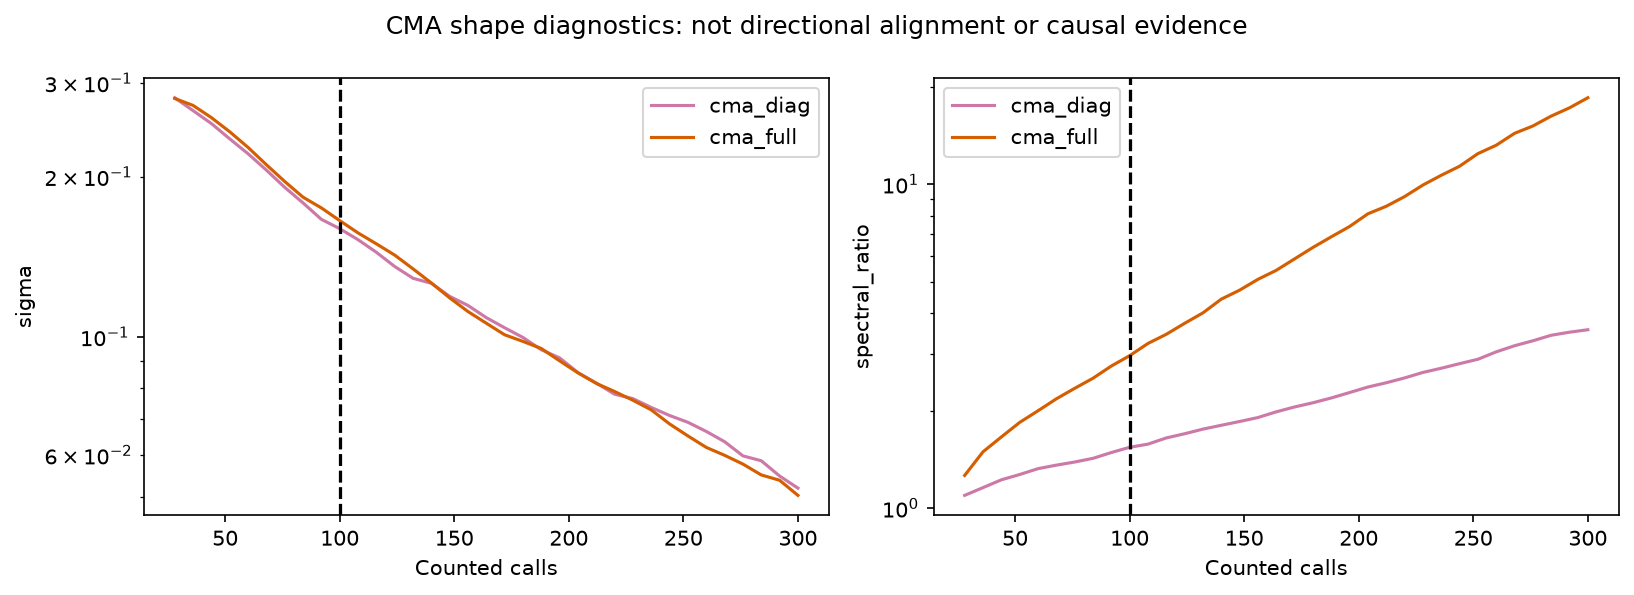

,method,calls,orientation,design_groups,estimate,low,high
0,cma_diag,100,404,20,-0.027347,-0.11311,0.063319
1,cma_diag,100,505,20,0.01778,-0.042533,0.078125
2,cma_diag,100,606,20,-0.022066,-0.083359,0.037617
3,cma_diag,300,404,20,0.013172,-0.065684,0.089429
4,cma_diag,300,505,20,0.022329,-0.040955,0.093488
5,cma_diag,300,606,20,-0.019012,-0.103,0.072725
6,cma_full,100,404,20,-0.027518,-0.14264,0.08019
7,cma_full,100,505,20,-0.046902,-0.13903,0.044918
8,cma_full,100,606,20,-0.019846,-0.12841,0.081283
9,cma_full,300,404,20,0.024916,-0.087023,0.13173


,method,orientation,design_groups,estimate,low,high
0,cma_diag,404,20,0.040519,-0.065776,0.14623
1,cma_diag,505,20,0.0045488,-0.090496,0.10537
2,cma_diag,606,20,0.0030539,-0.084008,0.1021
3,cma_full,404,20,0.052434,-0.0495,0.16263
4,cma_full,505,20,0.0035223,-0.10217,0.12325
5,cma_full,606,20,0.0053911,-0.0826,0.10144


,method,handler,calls,orientation,mean_boundary_fraction,mean_rejected_fraction,mean_repaired_fraction
44,cma_diag,project,100,-1,0.2227,0,0.27837
45,cma_diag,project,100,404,0.2326,0,0.29075
46,cma_diag,project,100,505,0.2265,0,0.28313
47,cma_diag,project,100,606,0.2153,0,0.26913
48,cma_diag,project,300,-1,0.1309,0,0.14025
49,cma_diag,project,300,404,0.13827,0,0.14814
50,cma_diag,project,300,505,0.12367,0,0.1325
51,cma_diag,project,300,606,0.12147,0,0.13014
52,cma_diag,resample,100,-1,0,0.23292,0
53,cma_diag,resample,100,404,0,0.23501,0


In [7]:
show("cma_budget_intervals",["block","method","handler","orientation",*CI])
show("quality_and_timing",["method","orientation","calls","median_rmse","mean_boundary_fraction"],"cma_ball")
picture("cma_adaptation")
show("boundary_intervals",["method","calls","orientation",*CI])
show("boundary_budget_intervals",["method","orientation",*CI])
show("quality_and_timing",["method","handler","calls","orientation","mean_boundary_fraction","mean_rejected_fraction","mean_repaired_fraction"],"cma_box")

## Target non-attainment and predictive assessment

Targets remain 6 mV and 10 mV from earlier development. Successful-run times are conditional and accompany hit rates; missing the target is retained. FUDS assessment follows the complete search and never guides recommendations. Existing FUDS profiles have already been inspected and are not untouched validation of later modelling decisions. Repeated searches are not independent battery measurements.

In [8]:
for block in ["battery_bo","cma_ball"]:
    print(block)
    show("target_summary",["method","calls","orientation","target_rmse_v","runs","hits","hit_rate","median_calls_if_reached","median_seconds_if_reached"],block)
show("heldout",["method","orientation","fuds80_rmse_v","fuds50_rmse_v"],"battery_bo")

battery_bo


,method,calls,orientation,target_rmse_v,runs,hits,hit_rate,median_calls_if_reached,median_seconds_if_reached
0,bo_ard,100,-1,0.006,20,18,0.9,68.5,14.541
1,bo_ard,100,-1,0.01,20,20,1,36.5,4.1397
2,bo_ard,100,404,0.006,20,12,0.6,59,10.933
3,bo_ard,100,404,0.01,20,19,0.95,43,5.622
4,bo_ard,100,505,0.006,20,12,0.6,74.5,13.728
5,bo_ard,100,505,0.01,20,19,0.95,40,4.336
6,bo_ard,100,606,0.006,20,8,0.4,70.5,12.676
7,bo_ard,100,606,0.01,20,19,0.95,39,4.7901
8,bo_ard_pool,100,-1,0.006,20,12,0.6,78,2.6813
9,bo_ard_pool,100,-1,0.01,20,20,1,30,0.44686


cma_ball


,method,calls,orientation,target_rmse_v,runs,hits,hit_rate,median_calls_if_reached,median_seconds_if_reached
56,cma_diag,100,-1,0.006,100,0,0,NaN,NaN
57,cma_diag,100,-1,0.01,100,46,0.46,66,0.10795
58,cma_diag,100,404,0.006,100,0,0,NaN,NaN
59,cma_diag,100,404,0.01,100,53,0.53,76,0.12362
60,cma_diag,100,505,0.006,100,0,0,NaN,NaN
61,cma_diag,100,505,0.01,100,41,0.41,70,0.11523
62,cma_diag,100,606,0.006,100,1,0.01,77,0.12529
63,cma_diag,100,606,0.01,100,51,0.51,66,0.10818
64,cma_diag,300,-1,0.006,100,47,0.47,252,0.41303
65,cma_diag,300,-1,0.01,100,100,1,112.5,0.18733


,method,orientation,fuds80_rmse_v,fuds50_rmse_v
0,bo_ard,-1,0.0059427,0.0052518
1,bo_ard,404,0.0064102,0.0060796
2,bo_ard,505,0.0061689,0.0064622
3,bo_ard,606,0.0073446,0.0066851
4,bo_ard_pool,-1,0.0068884,0.0059048
5,bo_ard_pool,404,0.0076987,0.0069658
6,bo_ard_pool,505,0.0076011,0.0074707
7,bo_ard_pool,606,0.0073957,0.0068131
8,bo_iso,-1,0.0072903,0.0071876
9,bo_iso,404,0.0073254,0.0072075


## Result-dependent findings and limits

The text below reports estimates mechanically from completed groups; it is not a universal algorithm ranking. Its intervals are pointwise and conditional on the chosen Qs. Supporting controls use fewer designs. Positive, negative and inconclusive outcomes are all retained. The selected high-condition quadratic is not a global description of the battery's curvature.

In [9]:
for filename, description in [
    ("kernel_by_search_intervals", "Kernel-by-search interaction"),
    ("bound_rotation_intervals", "Bound-induced rotation change"),
    ("boundary_budget_intervals", "CMA boundary-budget change")]:
    frame=read(filename)
    if frame.empty:
        print(description + ": insufficient complete groups.")
        continue
    sentences=[]
    for row in frame.to_dict("records"):
        label=", ".join(str(row[k]) for k in ["block","objective","method","orientation"] if k in row)
        direction="includes zero; direction remains uncertain" if row["low"] <= 0 <= row["high"] else ("positive in these groups" if row["low"] > 0 else "negative in these groups")
        sentences.append(f"- {label}: {row['estimate']:.3f} [{row['low']:.3f}, {row['high']:.3f}]; {direction} (n={row['design_groups']} designs).")
    display(Markdown("**"+description+"**\n\n"+"\n".join(sentences)))
print("Study status:",analysis["status"],"—",analysis["complete_runs"],"of",analysis["planned_runs"],"confirmation runs.")
print("Exact source IDs are retained in paired tables and checkpoints; validation.json hashes all generated outputs.")

**Kernel-by-search interaction**

- battery_bo, battery, 404: -0.019 [-0.133, 0.109]; includes zero; direction remains uncertain (n=20 designs).
- battery_bo, battery, 505: -0.008 [-0.115, 0.101]; includes zero; direction remains uncertain (n=20 designs).
- battery_bo, battery, 606: -0.111 [-0.169, -0.053]; negative in these groups (n=20 designs).
- quadratic_bo, quadratic, 404: -1.636 [-2.020, -1.243]; negative in these groups (n=10 designs).
- quadratic_bo, quadratic, 505: -1.649 [-1.939, -1.362]; negative in these groups (n=10 designs).
- quadratic_bo, quadratic, 606: -1.667 [-2.035, -1.286]; negative in these groups (n=10 designs).

**Bound-induced rotation change**

- battery, bo_ard_pool, 404: 0.007 [-0.136, 0.155]; includes zero; direction remains uncertain (n=10 designs).
- battery, bo_ard_pool, 505: -0.016 [-0.113, 0.082]; includes zero; direction remains uncertain (n=10 designs).
- battery, bo_ard_pool, 606: -0.005 [-0.182, 0.186]; includes zero; direction remains uncertain (n=10 designs).
- battery, bo_iso_pool, 404: 0.000 [0.000, 0.000]; includes zero; direction remains uncertain (n=10 designs).
- battery, bo_iso_pool, 505: 0.000 [0.000, 0.000]; includes zero; direction remains uncertain (n=10 designs).
- battery, bo_iso_pool, 606: 0.000 [0.000, 0.000]; includes zero; direction remains uncertain (n=10 designs).
- quadratic, bo_ard_pool, 404: -0.198 [-0.365, 0.034]; includes zero; direction remains uncertain (n=10 designs).
- quadratic, bo_ard_pool, 505: -0.243 [-0.456, 0.009]; includes zero; direction remains uncertain (n=10 designs).
- quadratic, bo_ard_pool, 606: -0.119 [-0.301, 0.072]; includes zero; direction remains uncertain (n=10 designs).
- quadratic, bo_iso_pool, 404: -0.000 [-0.000, 0.000]; includes zero; direction remains uncertain (n=10 designs).
- quadratic, bo_iso_pool, 505: -0.000 [-0.000, 0.000]; includes zero; direction remains uncertain (n=10 designs).
- quadratic, bo_iso_pool, 606: -0.000 [-0.000, 0.000]; includes zero; direction remains uncertain (n=10 designs).

**CMA boundary-budget change**

- cma_diag, 404: 0.041 [-0.066, 0.146]; includes zero; direction remains uncertain (n=20 designs).
- cma_diag, 505: 0.005 [-0.090, 0.105]; includes zero; direction remains uncertain (n=20 designs).
- cma_diag, 606: 0.003 [-0.084, 0.102]; includes zero; direction remains uncertain (n=20 designs).
- cma_full, 404: 0.052 [-0.050, 0.163]; includes zero; direction remains uncertain (n=20 designs).
- cma_full, 505: 0.004 [-0.102, 0.123]; includes zero; direction remains uncertain (n=20 designs).
- cma_full, 606: 0.005 [-0.083, 0.101]; includes zero; direction remains uncertain (n=20 designs).

Study status: complete — 3160 of 3160 confirmation runs.
Exact source IDs are retained in paired tables and checkpoints; validation.json hashes all generated outputs.


The group used complementary controls to separate the claims. Frozen-history GP agreement and acquisition replays motivated numerical-search diagnostics; corresponding scalar candidate pools restored physical path agreement to floating-point precision. Their poorer quadratic quality shows that restored agreement is not itself an optimisation improvement. ARD's remaining rotation effects under both acquisition procedures implicate coordinate representation together with fitting, rather than continuous acquisition search alone.

Five CMA replicates per initial design distinguish search variability from signed orientation effects. The 300-call diagonal penalties, alongside near-zero full-CMA estimates, support a budget-dependent difference; the mixed direct comparison at 100 calls limits a blanket sensitivity claim. Covariance, mean and step size adapt together, so these controls do not isolate covariance learning.

All V4 same-box handler-by-rotation intervals and their budget changes include zero. The group therefore retained the unresolved boundary result instead of generalising V3's orientation-specific finding. Later aligned V5 tests identity-ball quality, a different question, and is reported separately.

One cell, one window, cross-cell OCV, fixed capacity/SOC, selected domains and limited rotations constrain external validity. The evidence establishes neither practical equivalence, global battery conditioning, unique physical identification nor causal covariance alignment.
